# ENG2040 Assignment 1: Marketplace Orders and Delivery Outcomes

Imran Turganov

Pipeline from `data/raw.sql` to a model-ready feature table for `delivered_after_estimate`.

Run every step with one command from this folder:

```
uv run jupyter nbconvert --to notebook --execute --inplace assignment1.ipynb
```

All outputs are written to `outputs/`. Every step logs its runtime, memory and saved storage (Step 5).

## 0 Setup

In [1]:
import json
import platform
import resource
import sqlite3
import sys
import threading
import time
from contextlib import contextmanager
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import pyarrow

from setup_db import populate

ROOT = Path.cwd()
SQL_FILE = ROOT / "data" / "raw.sql"
SQL_DIR = ROOT / "sql"
OUT = ROOT / "outputs"
FIG = OUT / "figures"
CHART_DATA = OUT / "chart_data"
DB = OUT / "00_marketplace.sqlite"
for folder in [OUT, FIG, CHART_DATA]:
    folder.mkdir(exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
LATE, ON_TIME, GREY = "#c8553d", "#2d7d9a", "#9aa5ab"
UF = ["AC", "AL", "AM", "AP", "BA", "CE", "DF", "ES", "GO", "MA", "MG", "MS", "MT", "PA",
      "PB", "PE", "PI", "PR", "RJ", "RN", "RO", "RR", "RS", "SC", "SE", "SP", "TO"]

Resource measurement, same idea as `memlab.peak_memory()` from Lab 7: a thread samples the RSS of this process every 5 ms.
`peak_mb` is the growth over the RSS at the start of the step, so it covers pandas, NumPy and SQLite (all run inside this process).
`start_monitor()` / `stop_monitor()` do the same for steps that span several cells.

In [2]:
resources = []


def start_monitor(interval=0.005):
    process = psutil.Process()
    state = {"base": process.memory_info().rss, "start": time.perf_counter(), "done": threading.Event()}
    state["peak"] = state["base"]

    def watch():
        while not state["done"].is_set():
            state["peak"] = max(state["peak"], process.memory_info().rss)
            time.sleep(interval)

    state["thread"] = threading.Thread(target=watch, daemon=True)
    state["thread"].start()
    return state


def stop_monitor(state):
    state["done"].set()
    state["thread"].join()
    peak = max(state["peak"], psutil.Process().memory_info().rss)
    return {"peak_mb": round((peak - state["base"]) / 1e6, 1), "seconds": round(time.perf_counter() - state["start"], 2)}


@contextmanager
def peak_memory():
    state = start_monitor()
    result = {}
    yield result
    result.update(stop_monitor(state))


def file_mb(*paths):
    return round(sum(Path(path).stat().st_size for path in paths) / 1e6, 2)


def frame_mb(df):
    return round(df.memory_usage(deep=True).sum() / 1e6, 2)


def log_step(step, measured, estimate_mb, rows, outputs, temporary_mb=0.0):
    resources.append({
        "step": step,
        "seconds": measured["seconds"],
        "peak_rss_growth_mb": measured["peak_mb"],
        "estimated_peak_mb": round(estimate_mb, 1),
        "rows_out": rows,
        "saved_mb": file_mb(*outputs),
        "temporary_mb": temporary_mb,
        "outputs": ", ".join(Path(path).name for path in outputs),
    })

In [3]:
environment = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "processor": platform.machine(),
    "cpu_count": psutil.cpu_count(),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "sqlite": sqlite3.sqlite_version,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "pyarrow": pyarrow.__version__,
    "matplotlib": matplotlib.__version__,
    "psutil": psutil.__version__,
    "rss_after_imports_mb": round(psutil.Process().memory_info().rss / 1e6, 1),
}
(OUT / "environment.json").write_text(json.dumps(environment, indent=2))
environment

{'python': '3.12.13',
 'platform': 'macOS-15.8.1-arm64-arm-64bit',
 'processor': 'arm64',
 'cpu_count': 14,
 'ram_gb': 38.7,
 'sqlite': '3.50.4',
 'pandas': '2.3.3',
 'numpy': '2.3.3',
 'pyarrow': '22.0.0',
 'matplotlib': '3.10.7',
 'psutil': '7.2.2',
 'rss_after_imports_mb': 220.1}

## Step 0 Build the SQLite working copy

I use the supplied `populate()` from `setup_db.py` and rebuild the database on every run, so each run starts from the unchanged `raw.sql`.

**Estimate.** The loader reads the whole SQL file into one Python string (about 2 bytes per character, the reviews contain accents),
and SQLite writes pages of about the same size as the text. So peak memory is about 2 × 18 MB + 1.3 × 18 MB ≈ 60 MB and the database about 1.3 × the SQL file.

In [4]:
sql_mb = file_mb(SQL_FILE)
estimate = 2 * sql_mb + 1.3 * sql_mb
if DB.exists():
    DB.unlink()
with peak_memory() as m:
    n_tables, n_rows = populate(SQL_FILE, DB)
log_step("0 build database", m, estimate, n_rows, [DB])
con = sqlite3.connect(DB)
print(f"{n_tables} tables, {n_rows:,} rows | raw.sql {sql_mb} MB -> database {file_mb(DB)} MB | estimate {estimate:.0f} MB | {m}")

8 tables, 116,981 rows | raw.sql 18.26 MB -> database 24.36 MB | estimate 60 MB | {'peak_mb': 185.4, 'seconds': 0.24}


The measured peak is about 3 times my estimate. The reason is the Python string: the reviews contain emoji,
so Python stores every character of the 18 MB file with 4 bytes, not 2.
Then 73 MB (string) + 18 MB (file bytes while decoding) + 18 MB (UTF-8 copy passed to SQLite) + SQLite pages ≈ 140-180 MB.

In [5]:
sql_text = SQL_FILE.read_text()
print("characters:", f"{len(sql_text):,}", "| Python string:", round(sys.getsizeof(sql_text) / 1e6, 1), "MB | widest character:", repr(max(sql_text)))
del sql_text

characters: 18,253,192 | Python string: 73.0 MB | widest character: '🤔'


## Step 1 Loading the data

### 1.1 Tables and keys

In [6]:
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name", con)["name"]
rows = []
for table in tables:
    info = pd.read_sql(f"PRAGMA table_info({table})", con)
    rows.append({
        "table": table,
        "rows": con.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0],
        "columns": len(info),
        "primary_key": ", ".join(info.loc[info["pk"] > 0].sort_values("pk")["name"]),
    })
table_overview = pd.DataFrame(rows)
table_overview.to_csv(OUT / "01_tables.csv", index=False)
table_overview

,table,rows,columns,primary_key
0,category_translation,73,2,product_category_name
1,customers,20000,5,customer_id
2,order_items,22662,7,"order_id, order_item_id"
3,order_payments,20875,5,"order_id, payment_sequential"
4,order_reviews,19966,7,"review_id, order_id"
5,orders,20000,8,order_id
6,products,11334,9,product_id
7,sellers,2071,4,seller_id


| Table | One row is | Key | Link |
|---|---|---|---|
| `orders` | one order | `order_id` | central table |
| `customers` | the customer record of one order | `customer_id` | 1:1 with `orders.customer_id` |
| `order_items` | one purchased item | `order_id`, `order_item_id` | many per order, points to product and seller |
| `order_payments` | one payment record | `order_id`, `payment_sequential` | many per order |
| `order_reviews` | one review | `review_id`, `order_id` | usually one per order |
| `products` | one catalogue product | `product_id` | many items per product |
| `sellers` | one seller | `seller_id` | many items per seller |
| `category_translation` | one category name | `product_category_name` | Portuguese to English |

Relationship checks run in SQLite:

In [7]:
relationships = pd.read_sql((SQL_DIR / "01_relationships.sql").read_text(), con)
relationships.to_csv(OUT / "01_relationships.csv", index=False)
relationships

,relationship,unmatched_rows
0,orders -> customers,769
1,customers -> orders,769
2,order_items -> orders,0
3,order_items -> products,910
4,order_items -> sellers,893
5,order_payments -> orders,0
6,order_reviews -> orders,0
7,orders without items,142
8,orders without payments,0
9,orders without reviews,147


### 1.2 One row per order

Each child table is grouped to order level inside SQLite, then LEFT JOINed to `orders` (`sql/01_orders.sql`).
LEFT JOIN keeps every order, also orders without items or a customer record. Grouping before joining stops the items × payments fan-out.

**Estimate.** 20,000 rows × (12 text columns × ~75 B per Python string + 11 numeric columns × 8 B) ≈ 20 MB.

In [8]:
n_orders = con.execute("SELECT COUNT(*) FROM orders").fetchone()[0]
estimate = n_orders * (12 * 75 + 11 * 8) / 1e6
with peak_memory() as m_sql:
    orders_raw = pd.read_sql((SQL_DIR / "01_orders.sql").read_text(), con)
print(orders_raw.shape, "| in memory", frame_mb(orders_raw), "MB | estimate", round(estimate, 1), "MB |", m_sql)
orders_raw.head(3)

(20000, 23) | in memory 17.61 MB | estimate 19.8 MB | {'peak_mb': 37.0, 'seconds': 0.14}


,order_id,customer_id,customer_found,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,n_item_rows,n_products,n_sellers,items_price_raw,items_freight_raw,n_payment_rows,n_payment_values,payment_raw_centavos,payment_abs_centavos,n_review_rows
0,000e562887b1f2006d75e0be9558292e,2b01d668726fb0b751c55918c0437b7b,1,b2c72d1e9f6430603b8337d8f1394a99,11533,cubatao,SP,not_reported,2018-02-22 11:54:42,2018-02-22 12:08:37,2018-02-26 14:18:32,2018-03-12 18:46:34,2018-03-19 00:00:00,1,1,1,25.00,16.11,1,1,4111.0,4111.0,1
1,000e906b789b55f64edcb1f84030f90d,6a3b2fc9f270df258605e22bef19fd88,1,3588484a539617d91500764822230fb6,18900,santa cruz do rio pardo,SP,delivered,2017-11-21 18:54:23,2017-11-21 19:09:02,2017-11-22 20:46:54,2017-12-09 17:27:23,2017-12-07 00:00:00,1,1,1,21.99,11.85,1,1,3384.0,3384.0,1
2,0013503b13da1eac686219390b7d641b,f7277fce45fad3165379c15cacf5ddbe,1,1544f85dff3797491b60f2a5241d14c1,06160,osasco,SP,delivered,2017-12-05 23:40:59,2017-12-07 03:16:36,2017-12-07 22:59:30,2017-11-30 03:16:36,2017-12-28 00:00:00,1,1,1,119.90,17.32,1,1,13722.0,13722.0,1


### 1.3 Alternatives

- **B**: load the five tables into pandas and aggregate there.
- **C**: join everything first (naive). One order with 3 items and 2 payments becomes 6 rows, so totals are inflated.

In [9]:
def load_with_pandas():
    raw = {table: pd.read_sql(f"SELECT * FROM {table}", con)
           for table in ["orders", "customers", "order_items", "order_payments", "order_reviews"]}
    items = raw["order_items"].groupby("order_id").agg(
        n_item_rows=("order_item_id", "size"),
        items_price_raw=("price", "sum"),
        items_freight_raw=("freight_value", "sum"),
    )
    payments = raw["order_payments"].groupby("order_id").agg(
        n_payment_rows=("payment_sequential", "size"),
        payment_raw_centavos=("payment_value", "sum"),
    )
    reviews = raw["order_reviews"].groupby("order_id").agg(n_review_rows=("review_id", "size"))
    merged = (raw["orders"].merge(raw["customers"], on="customer_id", how="left")
              .join(items, on="order_id").join(payments, on="order_id").join(reviews, on="order_id"))
    rows_moved = sum(len(df) for df in raw.values())
    mb_moved = sum(frame_mb(df) for df in raw.values())
    return merged, rows_moved, mb_moved


with peak_memory() as m_pandas:
    orders_pandas, pandas_rows, pandas_mb = load_with_pandas()

naive = pd.read_sql((SQL_DIR / "01_naive_join.sql").read_text(), con)
true_payment = con.execute("SELECT SUM(payment_value) FROM order_payments").fetchone()[0]

load_comparison = pd.DataFrame([
    {"approach": "A: aggregate in SQLite, then join (used)", "rows_to_python": len(orders_raw),
     "data_in_python_mb": frame_mb(orders_raw), "seconds": m_sql["seconds"], "peak_rss_growth_mb": m_sql["peak_mb"],
     "payment_total_centavos": orders_raw["payment_raw_centavos"].sum()},
    {"approach": "B: load 5 tables into pandas, aggregate there", "rows_to_python": pandas_rows,
     "data_in_python_mb": pandas_mb, "seconds": m_pandas["seconds"], "peak_rss_growth_mb": m_pandas["peak_mb"],
     "payment_total_centavos": orders_pandas["payment_raw_centavos"].sum()},
    {"approach": "C: join all, then aggregate (naive)", "rows_to_python": int(naive.loc[0, "joined_rows"]),
     "data_in_python_mb": np.nan, "seconds": np.nan, "peak_rss_growth_mb": np.nan,
     "payment_total_centavos": naive.loc[0, "payment_raw_centavos"]},
])
load_comparison["payment_total_ok"] = np.isclose(load_comparison["payment_total_centavos"], true_payment)
load_comparison.to_csv(OUT / "01_load_comparison.csv", index=False)
load_comparison

,approach,rows_to_python,data_in_python_mb,seconds,peak_rss_growth_mb,payment_total_centavos,payment_total_ok
0,"A: aggregate in SQLite, then join (used)",20000,17.61,0.14,37.0,280524473.0,True
1,"B: load 5 tables into pandas, aggregate there",103503,36.53,0.14,47.5,280524473.0,True
2,"C: join all, then aggregate (naive)",23797,NaN,NaN,NaN,356439654.0,False


### 1.4 Checks: records, counts and totals are preserved

In [10]:
def source(query):
    return con.execute(query).fetchone()[0]


pandas_aligned = orders_pandas.set_index("order_id").loc[orders_raw["order_id"]]
checks = pd.DataFrame([
    ["rows = orders", len(orders_raw), source("SELECT COUNT(*) FROM orders")],
    ["order_id unique", int(orders_raw["order_id"].is_unique), 1],
    ["item rows", orders_raw["n_item_rows"].sum(), source("SELECT COUNT(*) FROM order_items")],
    ["payment rows", orders_raw["n_payment_rows"].sum(), source("SELECT COUNT(*) FROM order_payments")],
    ["review rows", orders_raw["n_review_rows"].sum(), source("SELECT COUNT(*) FROM order_reviews")],
    ["price total (BRL)", orders_raw["items_price_raw"].sum(), source("SELECT SUM(price) FROM order_items")],
    ["freight total (BRL)", orders_raw["items_freight_raw"].sum(), source("SELECT SUM(freight_value) FROM order_items")],
    ["payment total (centavos)", orders_raw["payment_raw_centavos"].sum(), source("SELECT SUM(payment_value) FROM order_payments")],
    ["orders with customer record", orders_raw["customer_found"].sum(),
     source("SELECT COUNT(*) FROM orders WHERE customer_id IN (SELECT customer_id FROM customers)")],
    ["same item totals as approach B", int(np.allclose(pandas_aligned["items_price_raw"].fillna(0), orders_raw["items_price_raw"].fillna(0))), 1],
    ["same payment totals as approach B", int(np.allclose(pandas_aligned["payment_raw_centavos"].fillna(0), orders_raw["payment_raw_centavos"].fillna(0))), 1],
], columns=["check", "pipeline", "source"])
checks["ok"] = np.isclose(checks["pipeline"].astype(float), checks["source"].astype(float))
checks.to_csv(OUT / "01_checks.csv", index=False)
assert checks["ok"].all()
checks

,check,pipeline,source,ok
0,rows = orders,2.000000e+04,2.000000e+04,True
1,order_id unique,1.000000e+00,1.000000e+00,True
2,item rows,2.266200e+04,2.266200e+04,True
3,payment rows,2.087500e+04,2.087500e+04,True
4,review rows,1.996600e+04,1.996600e+04,True
5,price total (BRL),5.444621e+07,5.444621e+07,True
6,freight total (BRL),1.051506e+07,1.051506e+07,True
7,payment total (centavos),2.805245e+08,2.805245e+08,True
8,orders with customer record,1.923100e+04,1.923100e+04,True
9,same item totals as approach B,1.000000e+00,1.000000e+00,True


### 1.5 Save

Parquet keeps the column types and is compressed. I write a CSV once only to compare sizes and delete it.

In [11]:
with peak_memory() as m_save:
    orders_raw.to_parquet(OUT / "01_orders_loaded.parquet", index=False)
orders_raw.to_csv(OUT / "tmp_orders_loaded.csv", index=False)
csv_mb = file_mb(OUT / "tmp_orders_loaded.csv")
(OUT / "tmp_orders_loaded.csv").unlink()
print("parquet", file_mb(OUT / "01_orders_loaded.parquet"), "MB | csv", csv_mb, "MB")

step1 = {"seconds": m_sql["seconds"] + m_save["seconds"], "peak_mb": max(m_sql["peak_mb"], m_save["peak_mb"])}
log_step("1 load one row per order", step1, estimate, len(orders_raw),
         [OUT / "01_orders_loaded.parquet", OUT / "01_checks.csv", OUT / "01_relationships.csv", OUT / "01_tables.csv", OUT / "01_load_comparison.csv"],
         temporary_mb=csv_mb)

parquet 3.36 MB | csv 5.29 MB


## Step 2 Data quality and cleaning

Rules I follow:
- no order is deleted, the cleaned table still has 20,000 rows;
- a value is changed only when the evidence shows what it should be, otherwise it becomes missing;
- every changed value goes to `02_change_log.csv` (table, key, column, old, new, rule);
- an order whose outcome is cancelled, unknown or unreliable gets a reason instead of a label.

### 2.1 Profile

**Estimate.** Step 2 loads the other tables (items 23k, customers 20k, payments 21k, reviews 20k with free text, products 11k rows;
about 30 MB as Python objects), keeps a cleaned copy of orders and items (about 30 MB) and a change log (about 5 MB), so about 65 MB.

In [12]:
monitor = start_monitor()
items_raw = pd.read_sql((SQL_DIR / "02_items.sql").read_text(), con)
products_raw = pd.read_sql("SELECT * FROM products", con)
sellers_raw = pd.read_sql("SELECT * FROM sellers", con)
customers_raw = pd.read_sql("SELECT * FROM customers", con)
payments_raw = pd.read_sql("SELECT * FROM order_payments", con)
reviews_raw = pd.read_sql("SELECT * FROM order_reviews", con)
translation = pd.read_sql("SELECT * FROM category_translation", con)

profile = pd.DataFrame({
    "missing": orders_raw.isna().sum(),
    "distinct": orders_raw.nunique(),
    "example": orders_raw.apply(lambda column: column.dropna().iloc[0] if column.notna().any() else None),
})
profile

,missing,distinct,example
order_id,0,20000,000e562887b1f2006d75e0be9558292e
customer_id,0,20000,2b01d668726fb0b751c55918c0437b7b
customer_found,0,2,1
customer_unique_id,1626,18259,b2c72d1e9f6430603b8337d8f1394a99
customer_zip_code_prefix,1060,8347,11533
customer_city,1062,2575,cubatao
customer_state,1064,53,SP
order_status,0,14,not_reported
order_purchase_timestamp,168,19652,2018-02-22 11:54:42
order_approved_at,199,19224,2018-02-22 12:08:37


In [13]:
for column in ["order_status", "customer_state"]:
    print(column, orders_raw[column].map(repr).value_counts().to_dict(), "\n")
print("payment_type", payments_raw["payment_type"].map(repr).value_counts().to_dict(), "\n")
print("review_score", reviews_raw["review_score"].value_counts(dropna=False).sort_index().to_dict())

order_status {"'delivered'": 17161, "'canceled'": 836, "'not_reported'": 804, "'  DELIVERED '": 769, "'shipped'": 207, "'unavailable'": 102, "'invoiced'": 57, "'processing'": 48, "'  SHIPPED '": 7, "'  UNAVAILABLE '": 4, "'  CANCELED '": 2, "'approved'": 1, "'  INVOICED '": 1, "'created'": 1} 

customer_state {"'SP'": 7229, "'RJ'": 2241, "'MG'": 2017, 'None': 1064, "'RS'": 899, "'PR'": 897, "'ZZ'": 838, "'SC'": 649, "'BA'": 591, "' sp  '": 387, "'DF'": 364, "'GO'": 344, "'ES'": 327, "'PE'": 262, "'CE'": 219, "'MT'": 163, "'PA'": 159, "'MA'": 143, "'MS'": 130, "' rj  '": 107, "' mg  '": 96, "'PI'": 95, "'PB'": 89, "'RN'": 88, "'AL'": 83, "'SE'": 69, "'TO'": 57, "' rs  '": 46, "' pr  '": 44, "'RO'": 43, "'AM'": 27, "' sc  '": 22, "' ba  '": 22, "' pe  '": 22, "' go  '": 21, "' es  '": 16, "' df  '": 15, "' ce  '": 15, "'AC'": 15, "' ma  '": 12, "'RR'": 12, "' mt  '": 10, "' ms  '": 10, "'AP'": 9, "' rn  '": 7, "' pa  '": 6, "' al  '": 4, "' to  '": 3, "' pi  '": 3, "' ac  '": 2, "' ro  '

In [14]:
DATE_COLUMNS = {
    "order_purchase_timestamp": "purchase_at",
    "order_approved_at": "approved_at",
    "order_delivered_carrier_date": "carrier_at",
    "order_delivered_customer_date": "delivered_at",
    "order_estimated_delivery_date": "estimated_at",
}
parsed = {new: pd.to_datetime(orders_raw[old], format="%Y-%m-%d %H:%M:%S", errors="coerce") for old, new in DATE_COLUMNS.items()}
date_profile = pd.DataFrame({
    old: {
        "missing": orders_raw[old].isna().sum(),
        "invalid": (orders_raw[old].notna() & parsed[new].isna()).sum(),
        "invalid_values": ", ".join(orders_raw.loc[orders_raw[old].notna() & parsed[new].isna(), old].unique()),
        "min": parsed[new].min(),
        "max": parsed[new].max(),
    }
    for old, new in DATE_COLUMNS.items()
}).T
date_profile

,missing,invalid,invalid_values,min,max
order_purchase_timestamp,168,165,2018-02-30 10:00:00,2016-10-03 21:13:36,2018-10-01 15:30:09
order_approved_at,199,152,2018-02-30 10:00:00,2016-10-04 13:26:11,2018-08-29 10:35:16
order_delivered_carrier_date,483,149,2018-02-30 10:00:00,2016-10-09 03:45:42,2018-08-31 15:09:00
order_delivered_customer_date,714,161,2018-02-30 10:00:00,2016-09-29 15:46:26,2018-10-17 13:22:46
order_estimated_delivery_date,160,170,2018-02-30 10:00:00,2016-11-23 00:00:00,2018-10-23 00:00:00


The same placeholder `2018-02-30 10:00:00` (an impossible date) appears in every date column.
Below I check how delivery dates relate to approval: many are exactly 7 days before approval, to the second.

In [15]:
seven_days = pd.Timedelta(days=7)
before_approval = parsed["delivered_at"] < parsed["approved_at"]
exactly_seven = (parsed["delivered_at"] == parsed["approved_at"] - seven_days) | (parsed["delivered_at"] == parsed["purchase_at"] - seven_days)
print("delivered before approval:", before_approval.sum(), "| of these exactly 7 days before approval or purchase:", (before_approval & exactly_seven).sum())
print("delivered before purchase:", (parsed["delivered_at"] < parsed["purchase_at"]).sum())
print("delivered before carrier pickup:", (parsed["delivered_at"] < parsed["carrier_at"]).sum())
status = orders_raw["order_status"].str.strip().str.lower()
pd.crosstab(status, parsed["delivered_at"].notna(), margins=True).rename(columns={False: "no delivery date", True: "has delivery date"})

delivered before approval: 812 | of these exactly 7 days before approval or purchase: 803
delivered before purchase: 804
delivered before carrier pickup: 793


order_delivered_customer_date,no delivery date,has delivery date,All
order_status,,,
approved,1,0,1
canceled,105,733,838
created,1,0,1
delivered,338,17592,17930
invoiced,51,7,58
not_reported,24,780,804
processing,45,3,48
shipped,206,8,214
unavailable,104,2,106


In [16]:
def count(mask):
    return int(mask.fillna(False).astype(bool).sum())


def changed(series, new):
    return series.notna() & (series != new)


price, freight = items_raw["price"], items_raw["freight_value"]
product_numbers = ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]
issues = pd.DataFrame([
    ["orders", "order_status", "spaces / upper case", count(changed(orders_raw["order_status"], status))],
    ["orders", "order_status", "'not_reported' (unknown outcome)", count(status == "not_reported")],
    ["orders", "order_status", "cancelled but has a delivery date", count((status == "canceled") & parsed["delivered_at"].notna())],
    ["orders", "5 date columns", "'2018-02-30 10:00:00' placeholder", int(date_profile["invalid"].sum())],
    ["orders", "delivered date", "exactly 7 days before approval", count(before_approval & exactly_seven)],
    ["orders", "delivered date", "before approval (other)", count(before_approval & ~exactly_seven)],
    ["orders", "customer_id", "no customer record", count(orders_raw["customer_found"] == 0)],
    ["customers", "customer_state", "'ZZ' or missing", count(~customers_raw["customer_state"].str.strip().str.upper().isin(UF))],
    ["customers", "customer_state", "lower case", count(changed(customers_raw["customer_state"], customers_raw["customer_state"].str.upper()))],
    ["customers", "customer_city", "upper case with spaces", count(changed(customers_raw["customer_city"], customers_raw["customer_city"].str.strip().str.lower()))],
    ["customers", "zip prefix", "'12A?0' placeholder", count(customers_raw["customer_zip_code_prefix"] == "12A?0")],
    ["customers", "customer_unique_id", "missing", count(customers_raw["customer_unique_id"].isna())],
    ["order_items", "price", "negative", count(price < 0)],
    ["order_items", "price", "above 6,500 BRL (x1000)", count(price.abs() > 6500)],
    ["order_items", "price", "missing", count(price.isna())],
    ["order_items", "freight_value", "negative", count(freight < 0)],
    ["order_items", "freight_value", "above 500 BRL (x1000)", count(freight.abs() > 500)],
    ["order_items", "freight_value", "missing", count(freight.isna())],
    ["order_items", "product_id", "not in products", count(~items_raw["product_id"].isin(products_raw["product_id"]))],
    ["order_items", "seller_id", "not in sellers", count(~items_raw["seller_id"].isin(sellers_raw["seller_id"]))],
    ["order_items", "all but order_item_id", "identical rows (several units of one product)", count(items_raw.drop(columns="order_item_id").duplicated())],
    ["products", "category", "upper case with spaces", count(changed(products_raw["product_category_name"], products_raw["product_category_name"].str.strip().str.lower()))],
    ["products", "category", "'unmapped_category' or missing", count(products_raw["product_category_name"].isna() | (products_raw["product_category_name"] == "unmapped_category"))],
    ["products", "name / description / photos", "-1 placeholder", count((products_raw[["product_name_lenght", "product_description_lenght", "product_photos_qty"]] < 0).any(axis=1))],
    ["products", "weight / dimensions", "negative", count((products_raw[product_numbers] < 0).any(axis=1))],
    ["products", "weight / dimensions", "x1000 (>45 kg or >1000 cm)", count((products_raw["product_weight_g"].abs() > 45000) | (products_raw[product_numbers[1:]].abs() > 1000).any(axis=1))],
    ["products", "any attribute", "missing", count(products_raw.isna().any(axis=1))],
    ["sellers", "seller_state", "'zz' or missing", count(~sellers_raw["seller_state"].str.strip().str.upper().isin(UF))],
    ["sellers", "seller_state", "lower case", count(changed(sellers_raw["seller_state"], sellers_raw["seller_state"].str.strip().str.upper()))],
    ["sellers", "seller_city", "upper case", count(changed(sellers_raw["seller_city"], sellers_raw["seller_city"].str.strip().str.lower()))],
    ["order_payments", "payment_value", "negative", count(payments_raw["payment_value"] < 0)],
    ["order_payments", "payment_value", "missing", count(payments_raw["payment_value"].isna())],
    ["order_payments", "payment_type", "spaces / upper case", count(changed(payments_raw["payment_type"], payments_raw["payment_type"].str.strip().str.lower()))],
    ["order_payments", "payment_type", "'unclassified_payment'", count(payments_raw["payment_type"] == "unclassified_payment")],
    ["order_payments", "payment_installments", "-1", count(payments_raw["payment_installments"] < 0)],
    ["order_reviews", "review_score", "0 or 8 (outside 1-5)", count(~reviews_raw["review_score"].between(1, 5) & reviews_raw["review_score"].notna())],
    ["order_reviews", "review_id", "duplicated", count(reviews_raw["review_id"].duplicated())],
], columns=["table", "field", "problem", "rows"])
issues.to_csv(OUT / "02_issues.csv", index=False)
issues

,table,field,problem,rows
0,orders,order_status,spaces / upper case,783
1,orders,order_status,'not_reported' (unknown outcome),804
2,orders,order_status,cancelled but has a delivery date,733
3,orders,5 date columns,'2018-02-30 10:00:00' placeholder,797
4,orders,delivered date,exactly 7 days before approval,803
5,orders,delivered date,before approval (other),9
6,orders,customer_id,no customer record,769
7,customers,customer_state,'ZZ' or missing,1185
8,customers,customer_state,lower case,914
9,customers,customer_city,upper case with spaces,895


### 2.2 Change log

`fix()` changes the rows of one column where `mask` is true and writes old and new values to the log.

In [17]:
changes = []


def fix(df, mask, column, new, rule, table, key):
    mask = mask.fillna(False).astype(bool)
    changes.append(pd.DataFrame({
        "table": table,
        "key": df.loc[mask, key].astype(str),
        "column": column,
        "old": df.loc[mask, column].astype(str),
        "new": new[mask].astype(str),
        "rule": rule,
    }))
    df.loc[mask, column] = new[mask]
    return int(mask.sum())


def missing(df):
    return pd.Series(np.nan, index=df.index)

### 2.3 Orders: status and dates

Status: strip spaces and lower case. Dates: the placeholder becomes missing, then every column is parsed with one exact format.
No time zone is applied, the recorded local clock is used as it is.

In [18]:
orders = orders_raw.copy()
orders["customer_found"] = orders["customer_found"].astype(bool)
fix(orders, changed(orders["order_status"], status), "order_status", status, "strip spaces, lower case", "orders", "order_id")
for old, new in DATE_COLUMNS.items():
    fix(orders, orders[old].notna() & parsed[new].isna(), old, missing(orders), "impossible date -> missing", "orders", "order_id")
    orders[new] = pd.to_datetime(orders[old], format="%Y-%m-%d %H:%M:%S")
orders = orders.drop(columns=list(DATE_COLUMNS))
orders["order_status"].value_counts()

order_status
delivered       17930
canceled          838
not_reported      804
shipped           214
unavailable       106
invoiced           58
processing         48
approved            1
created             1
Name: count, dtype: int64

### 2.4 Customer location

States are upper-cased. `ZZ` and missing states are recovered from the first 3 digits of the zip code:
in all valid customer records every 3-digit prefix belongs to exactly one state, so the lookup is unambiguous.
I do not add seller records to the lookup: 13 prefixes would then get a second state from a single seller, so seller states are less reliable.
`12A?0` zip codes become missing. Orders without a customer record keep an unknown state.

In [19]:
known = customers_raw[["customer_zip_code_prefix", "customer_state"]].set_axis(["zip", "state"], axis=1)
known["state"] = known["state"].str.strip().str.upper()
known = known[known["state"].isin(UF) & known["zip"].str.fullmatch(r"\d{5}", na=False)]
known["zip3"] = known["zip"].str[:3]
states_per_prefix = known.groupby("zip3")["state"].nunique()
assert (states_per_prefix == 1).all()
zip3_state = known.groupby("zip3")["state"].first()
print("zip prefixes:", len(zip3_state), "| prefixes with more than one state:", (states_per_prefix > 1).sum())

zip prefixes: 819 | prefixes with more than one state: 0


In [20]:
state = orders["customer_state"].str.strip().str.upper()
fix(orders, changed(orders["customer_state"], state), "customer_state", state, "strip spaces, upper case", "orders", "order_id")
fix(orders, orders["customer_zip_code_prefix"] == "12A?0", "customer_zip_code_prefix", missing(orders), "placeholder -> missing", "orders", "order_id")
city = orders["customer_city"].str.strip().str.lower()
fix(orders, changed(orders["customer_city"], city), "customer_city", city, "strip spaces, lower case", "orders", "order_id")

invalid_state = orders["customer_found"] & ~orders["customer_state"].isin(UF)
recovered = orders["customer_zip_code_prefix"].str[:3].map(zip3_state)
orders["state_source"] = np.where(~orders["customer_found"], "no customer record", np.where(invalid_state, "zip prefix", "recorded"))
fix(orders, invalid_state & recovered.notna(), "customer_state", recovered, "'ZZ'/missing -> state of zip prefix", "orders", "order_id")
still_invalid = orders["customer_state"].notna() & ~orders["customer_state"].isin(UF)
fix(orders, still_invalid, "customer_state", missing(orders), "placeholder -> missing", "orders", "order_id")
orders.loc[orders["customer_found"] & orders["customer_state"].isna(), "state_source"] = "unknown"
orders["state_source"].value_counts()

state_source
recorded              18098
zip prefix             1132
no customer record      769
unknown                   1
Name: count, dtype: int64

### 2.5 Items, prices and freight

Negative prices, freight and payments are sign errors: with absolute values the order total matches the paid total.
Very large values are a ×1000 unit error. I picked the limits from single-item orders with complete payments:
up to 6,500 BRL a price matches the payment as it is, above 6,500 it matches only after dividing by 1000 (same for freight above 500).

In [21]:
items = items_raw.copy()
items["item_key"] = items["order_id"] + "/" + items["order_item_id"].astype(str)
for column in ["price", "freight_value"]:
    fix(items, items[column] < 0, column, items[column].abs(), "negative -> absolute value", "order_items", "item_key")

orders["paid_brl"] = (orders["payment_abs_centavos"] / 100).where(orders["n_payment_values"] == orders["n_payment_rows"])
single = items[items["order_id"].map(items["order_id"].value_counts()) == 1].copy()
single["paid"] = single["order_id"].map(orders.set_index("order_id")["paid_brl"])
single = single.dropna(subset=["paid", "price", "freight_value"])
price_ok = single["price"].where(single["price"] <= 6500, single["price"] / 1000)
freight_ok = single["freight_value"].where(single["freight_value"] <= 500, single["freight_value"] / 1000)

evidence = []
for column, value, other, bins in [
    ("price", single["price"], freight_ok, [0, 1000, 6500, np.inf]),
    ("freight_value", single["freight_value"], price_ok, [-0.01, 100, 500, np.inf]),
]:
    table = pd.DataFrame({
        "range": pd.cut(value, bins),
        "as_is": np.isclose(single["paid"], value + other, atol=0.011),
        "divided": np.isclose(single["paid"], value / 1000 + other, atol=0.011) & ~np.isclose(single["paid"], value + other, atol=0.011),
    }).groupby("range", observed=True).agg(items=("as_is", "size"), match_as_is=("as_is", "sum"), match_after_divide_1000=("divided", "sum"))
    evidence.append(table.reset_index().assign(column=column))
unit_evidence = pd.concat(evidence)[["column", "range", "items", "match_as_is", "match_after_divide_1000"]]
unit_evidence.to_csv(OUT / "02_unit_evidence.csv", index=False)
unit_evidence

,column,range,items,match_as_is,match_after_divide_1000
0,price,"(0.0, 1000.0]",15986,15189,0
1,price,"(1000.0, 6500.0]",143,136,0
2,price,"(6500.0, inf]",309,0,301
0,freight_value,"(-0.01, 100.0]",15971,15181,1
1,freight_value,"(100.0, 500.0]",102,96,0
2,freight_value,"(500.0, inf]",365,0,349


Identical item rows that differ only in `order_item_id` are not duplicates: one row is one unit (Appendix B), so an order of 3 equal units has 3 rows. They are kept.

In [22]:
fix(items, items["price"] > 6500, "price", items["price"] / 1000, "unit error: price > 6,500 -> / 1000", "order_items", "item_key")
fix(items, items["freight_value"] > 500, "freight_value", items["freight_value"] / 1000, "unit error: freight > 500 -> / 1000", "order_items", "item_key")

473

Second check for unit errors below the limit: compare each price with the median price of the same product in all orders.
After the fixes above, no item costs more than about 2.5 times its product's median, except a 1000-times outlier, which is the same unit error.

In [23]:
ratio = items["price"] / items.groupby("product_id")["price"].transform("median")
print("largest price / product median ratios:", ratio.nlargest(4).round(1).tolist())
fix(items, ratio > 100, "price", items["price"] / 1000, "unit error: 1000 x product median -> / 1000", "order_items", "item_key")

largest price / product median ratios: [1000.0, 2.5, 2.2, 2.0]


1

In [24]:
counts = items_raw.groupby("order_id").agg(n=("price", "size"), price_known=("price", "count"), freight_known=("freight_value", "count"))
complete = counts.index[(counts["price_known"] == counts["n"]) & (counts["freight_known"] == counts["n"])]
check = orders.set_index("order_id").loc[complete]
check = check[check["n_payment_values"] == check["n_payment_rows"]]
raw_total = items_raw.groupby("order_id")[["price", "freight_value"]].sum().sum(axis=1)
abs_total = items_raw[["price", "freight_value"]].abs().groupby(items_raw["order_id"]).sum().sum(axis=1)
clean_total = items.groupby("order_id")[["price", "freight_value"]].sum().sum(axis=1)
reconciliation = pd.DataFrame({
    "stage": ["raw values", "signs fixed", "signs and units fixed"],
    "orders_matching_payment": [
        int(np.isclose(raw_total.loc[check.index], check["payment_raw_centavos"] / 100, atol=0.011).sum()),
        int(np.isclose(abs_total.loc[check.index], check["paid_brl"], atol=0.011).sum()),
        int(np.isclose(clean_total.loc[check.index], check["paid_brl"], atol=0.011).sum()),
    ],
})
reconciliation["orders_checked"] = len(check)
reconciliation["share"] = (reconciliation["orders_matching_payment"] / len(check)).round(3)
reconciliation.to_csv(OUT / "02_payment_reconciliation.csv", index=False)
reconciliation

,stage,orders_matching_payment,orders_checked,share
0,raw values,14854,18122,0.820
1,signs fixed,16418,18122,0.906
2,signs and units fixed,17223,18122,0.950


Orders that still paid less than their items after the fixes could hide another unit error. I list them instead of guessing.

In [25]:
residual = check.assign(items_total=clean_total.loc[check.index])
residual = residual.loc[residual["paid_brl"] < residual["items_total"] - 1, ["n_item_rows", "paid_brl", "items_total"]]
residual.to_csv(OUT / "02_payment_residuals.csv")
residual

,n_item_rows,paid_brl,items_total
order_id,,,
320dcf288de15e4ff06ebbfce4e42c78,2,81.37,87.55
6dcf0aeb8b1eb4021c26e1d0e9394979,1,326.20,333.92
c6c17394464f987209982d3f1423f068,2,139.80,141.80


The orders that still do not match mostly paid **more** than the items (instalment interest on credit cards), which is normal.

### 2.6 Products and sellers

- category: strip spaces, lower case; `unmapped_category` becomes missing; English name from the translation table (Portuguese if no translation);
- `-1` in name length, description length and photos is a placeholder, so missing;
- negative weight or size is a sign error;
- weight above 45 kg or a side above 1000 cm is ×1000 (gap below: no real value between the limit and the flagged values).

In [26]:
LIMITS = {"product_weight_g": 45000, "product_length_cm": 1000, "product_height_cm": 1000, "product_width_cm": 1000}
size_evidence = pd.DataFrame({
    column: {
        "largest_value_kept": products_raw[column].abs()[products_raw[column].abs() <= limit].max(),
        "smallest_value_divided": products_raw[column].abs()[products_raw[column].abs() > limit].min(),
        "rows_divided": int((products_raw[column].abs() > limit).sum()),
    }
    for column, limit in LIMITS.items()
}).T
size_evidence.to_csv(OUT / "02_size_evidence.csv")
size_evidence

,largest_value_kept,smallest_value_divided,rows_divided
product_weight_g,40425.0,50000.0,89.0
product_length_cm,105.0,16000.0,94.0
product_height_cm,105.0,2000.0,92.0
product_width_cm,118.0,11000.0,84.0


In [27]:
products = products_raw.copy()
category = products["product_category_name"].str.strip().str.lower()
fix(products, changed(products["product_category_name"], category), "product_category_name", category, "strip spaces, lower case", "products", "product_id")
fix(products, products["product_category_name"] == "unmapped_category", "product_category_name", missing(products), "placeholder -> missing", "products", "product_id")
for column in ["product_name_lenght", "product_description_lenght", "product_photos_qty"]:
    fix(products, products[column] < 0, column, missing(products), "-1 placeholder -> missing", "products", "product_id")
for column, limit in LIMITS.items():
    fix(products, products[column] < 0, column, products[column].abs(), "negative -> absolute value", "products", "product_id")
    fix(products, products[column] > limit, column, products[column] / 1000, f"unit error: > {limit} -> / 1000", "products", "product_id")
products = products.merge(translation, on="product_category_name", how="left")
products["category"] = products["product_category_name_english"].fillna(products["product_category_name"])

sellers = sellers_raw.copy()
seller_state = sellers["seller_state"].str.strip().str.upper()
fix(sellers, changed(sellers["seller_state"], seller_state), "seller_state", seller_state, "strip spaces, upper case", "sellers", "seller_id")
seller_city = sellers["seller_city"].str.strip().str.lower()
fix(sellers, changed(sellers["seller_city"], seller_city), "seller_city", seller_city, "strip spaces, lower case", "sellers", "seller_id")
fix(sellers, sellers["seller_zip_code_prefix"] == "12A?0", "seller_zip_code_prefix", missing(sellers), "placeholder -> missing", "sellers", "seller_id")
seller_recovered = sellers["seller_zip_code_prefix"].str[:3].map(zip3_state)
fix(sellers, ~sellers["seller_state"].isin(UF) & seller_recovered.notna(), "seller_state", seller_recovered, "'ZZ'/missing -> state of zip prefix", "sellers", "seller_id")
fix(sellers, sellers["seller_state"].notna() & ~sellers["seller_state"].isin(UF), "seller_state", missing(sellers), "placeholder -> missing", "sellers", "seller_id")

items = (items.merge(products.drop(columns=["product_category_name_english"]), on="product_id", how="left")
         .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left"))
items["product_found"] = items["product_id"].isin(products["product_id"])
items["seller_found"] = items["seller_id"].isin(sellers["seller_id"])
print("items without product record:", (~items["product_found"]).sum(), "| without seller record:", (~items["seller_found"]).sum(),
      "| seller state unknown:", items["seller_state"].isna().sum())

items without product record: 910 | without seller record: 893 | seller state unknown: 893


### 2.7 Basket totals and delivery labels

Label reasons are checked in this order, the first match wins:

| Reason | Rule | Label |
|---|---|---|
| cancelled | status `canceled` | none |
| unknown status | status `not_reported` | none |
| not delivered | status shipped, invoiced, processing, unavailable, created, approved | none |
| no delivery date | delivered, but the date is missing or impossible | none |
| no estimated date | estimate missing or impossible | none |
| impossible chronology | delivered before purchase, or exactly 7 days before approval or purchase (shifted date) | none |
| labelled | everything else | 1 if delivery calendar date > estimated date, else 0 |

A delivery after purchase but before the recorded approval or carrier pickup keeps its label, flagged in `chronology_flag`:
the label needs only the delivery and estimated dates, and here the approval or carrier time is the doubtful one.

In [28]:
basket = (items.assign(price_missing=items["price"].isna(), freight_missing=items["freight_value"].isna())
          .groupby("order_id")
          .agg(price_total=("price", "sum"), freight_total=("freight_value", "sum"),
               n_price_missing=("price_missing", "sum"), n_freight_missing=("freight_missing", "sum")))
orders = orders.merge(basket, on="order_id", how="left")
orders.loc[orders["n_price_missing"] > 0, "price_total"] = np.nan
orders.loc[orders["n_freight_missing"] > 0, "freight_total"] = np.nan

NOT_DELIVERED = ["shipped", "invoiced", "processing", "unavailable", "created", "approved"]
shifted = ((orders["delivered_at"] == orders["approved_at"] - seven_days)
           | (orders["delivered_at"] == orders["purchase_at"] - seven_days))
impossible = (orders["delivered_at"] < orders["purchase_at"]) | shifted
orders["chronology_flag"] = ~impossible & ((orders["delivered_at"] < orders["approved_at"]) | (orders["delivered_at"] < orders["carrier_at"]))
orders["label_status"] = np.select(
    [orders["order_status"] == "canceled",
     orders["order_status"] == "not_reported",
     orders["order_status"].isin(NOT_DELIVERED),
     orders["delivered_at"].isna(),
     orders["estimated_at"].isna(),
     impossible],
    ["cancelled", "unknown status", "not delivered", "no delivery date", "no estimated date", "impossible chronology"],
    default="labelled",
)
orders["delay_days"] = (orders["delivered_at"].dt.normalize() - orders["estimated_at"].dt.normalize()).dt.days
orders["delivered_after_estimate"] = (orders["delay_days"] > 0).astype(float).where(orders["label_status"] == "labelled")

accounting = pd.crosstab(orders["label_status"], orders["order_status"], margins=True, margins_name="total")
accounting.to_csv(OUT / "02_label_accounting.csv")
assert accounting.loc["total", "total"] == len(orders_raw) == len(orders)
print("labelled orders kept with chronology_flag:", (orders["chronology_flag"] & (orders["label_status"] == "labelled")).sum())
accounting

labelled orders kept with chronology_flag: 10


order_status,approved,canceled,created,delivered,invoiced,not_reported,processing,shipped,unavailable,total
label_status,,,,,,,,,,
cancelled,0,838,0,0,0,0,0,0,0,838
impossible chronology,0,0,0,782,0,0,0,0,0,782
labelled,0,0,0,16491,0,0,0,0,0,16491
no delivery date,0,0,0,338,0,0,0,0,0,338
no estimated date,0,0,0,319,0,0,0,0,0,319
not delivered,1,0,1,0,58,0,48,214,106,428
unknown status,0,0,0,0,0,804,0,0,0,804
total,1,838,1,17930,58,804,48,214,106,20000


In [29]:
change_log = pd.concat(changes, ignore_index=True)
change_summary = change_log.groupby(["table", "column", "rule"]).size().rename("values_changed").reset_index()

orders.to_parquet(OUT / "02_orders_clean.parquet", index=False)
items.to_parquet(OUT / "02_items_clean.parquet", index=False)
change_log.to_csv(OUT / "02_change_log.csv", index=False)
change_summary.to_csv(OUT / "02_change_summary.csv", index=False)

log_step("2 clean and label", stop_monitor(monitor), 65, len(orders),
         [OUT / "02_orders_clean.parquet", OUT / "02_items_clean.parquet", OUT / "02_change_log.csv", OUT / "02_change_summary.csv",
          OUT / "02_issues.csv", OUT / "02_label_accounting.csv", OUT / "02_unit_evidence.csv", OUT / "02_payment_reconciliation.csv",
          OUT / "02_payment_residuals.csv", OUT / "02_size_evidence.csv"])
print("changed values:", len(change_log), "| cleaned orders:", len(orders), "| labelled:", orders["delivered_after_estimate"].notna().sum())
change_summary

changed values: 11388 | cleaned orders: 20000 | labelled: 16491


,table,column,rule,values_changed
0,order_items,freight_value,negative -> absolute value,458
1,order_items,freight_value,unit error: freight > 500 -> / 1000,473
2,order_items,price,negative -> absolute value,408
3,order_items,price,unit error: 1000 x product median -> / 1000,1
4,order_items,price,"unit error: price > 6,500 -> / 1000",416
5,orders,customer_city,"strip spaces, lower case",860
6,orders,customer_state,'ZZ'/missing -> state of zip prefix,1132
7,orders,customer_state,placeholder -> missing,1
8,orders,customer_state,"strip spaces, upper case",877
9,orders,customer_zip_code_prefix,placeholder -> missing,900


## Step 3 Exploratory analysis

All numbers use the labelled orders. Rates have Wilson 95% confidence intervals.

**Estimate.** A copy of the labelled orders (16k rows, about 10 MB), small grouped tables and three matplotlib figures (about 10 MB each), so about 40 MB.

In [30]:
monitor = start_monitor()


def wilson(late, n, z=1.96):
    p = late / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centre - half, centre + half


def rate_table(df, by):
    table = df.groupby(by, observed=True).agg(orders=("delivered_after_estimate", "size"), late=("delivered_after_estimate", "sum"))
    table["late_rate"] = table["late"] / table["orders"]
    table["ci_low"], table["ci_high"] = wilson(table["late"], table["orders"])
    return table


lab = orders[orders["label_status"] == "labelled"].copy()
lab["approval_at"] = lab["approved_at"].fillna(lab["purchase_at"])
lab["lead_days"] = (lab["estimated_at"].dt.normalize() - lab["approved_at"].dt.normalize()).dt.days
lab["actual_days"] = (lab["delivered_at"].dt.normalize() - lab["approved_at"].dt.normalize()).dt.days
lab["month"] = lab["approval_at"].dt.to_period("M")
lab["is_sp"] = lab["customer_state"] == "SP"
overall = lab["delivered_after_estimate"].mean()

### Q1 How often are orders late, and how long are the delays?

In [31]:
late_orders = lab[lab["delivered_after_estimate"] == 1]
low, high = wilson(late_orders.shape[0], len(lab))
q1 = pd.Series({
    "labelled orders": len(lab),
    "late orders": len(late_orders),
    "late rate": overall,
    "ci low": low,
    "ci high": high,
    "delay median (days)": late_orders["delay_days"].median(),
    "delay mean (days)": late_orders["delay_days"].mean(),
    "delay p75 (days)": late_orders["delay_days"].quantile(0.75),
    "delay p90 (days)": late_orders["delay_days"].quantile(0.90),
    "delay max (days)": late_orders["delay_days"].max(),
    "late by more than 7 days (share of late)": (late_orders["delay_days"] > 7).mean(),
    "late by 1-3 days (share of late)": (late_orders["delay_days"] <= 3).mean(),
    "on-time: median days early": -lab.loc[lab["delay_days"] <= 0, "delay_days"].median(),
    "on-time: delivered on the estimated day": (lab["delay_days"] == 0).sum(),
}).round(4)
q1.to_csv(OUT / "03_q1_summary.csv")
q1

labelled orders                             16491.0000
late orders                                  1107.0000
late rate                                       0.0671
ci low                                          0.0634
ci high                                         0.0710
delay median (days)                             7.0000
delay mean (days)                              10.5736
delay p75 (days)                               13.0000
delay p90 (days)                               22.0000
delay max (days)                              188.0000
late by more than 7 days (share of late)        0.4463
late by 1-3 days (share of late)                0.2918
on-time: median days early                     13.0000
on-time: delivered on the estimated day       232.0000
dtype: float64

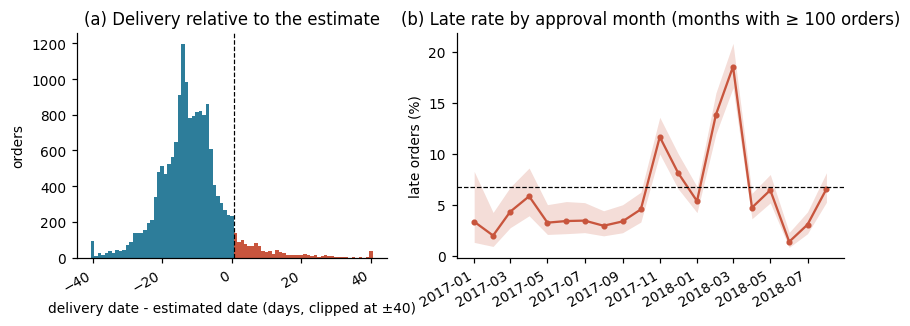

,orders,late,late_rate,ci_low,ci_high,lead_days,actual_days
month,,,,,,,
2018-03,1215,225.0,0.185185,0.164347,0.208008,22.0,13.0
2018-02,1136,157.0,0.138204,0.119351,0.159496,25.0,14.0
2017-11,1220,142.0,0.116393,0.099590,0.135605,23.0,12.0
2017-12,973,79.0,0.081192,0.065632,0.100046,27.0,12.0
2018-08,1132,74.0,0.065371,0.052391,0.081291,14.0,6.0


In [32]:
monthly = rate_table(lab, "month").join(lab.groupby("month")[["lead_days", "actual_days"]].median())
monthly.to_csv(CHART_DATA / "fig1_monthly_late_rate.csv")
delay_counts = lab["delay_days"].clip(-40, 40).value_counts().sort_index()
delay_counts.rename("orders").to_csv(CHART_DATA / "fig1_delay_histogram.csv")

fig, axes = plt.subplots(1, 2, figsize=(9, 3), gridspec_kw={"width_ratios": [1, 1.25]})
axes[0].bar(delay_counts.index, delay_counts.values, width=1, color=np.where(delay_counts.index > 0, LATE, ON_TIME))
axes[0].axvline(0.5, color="black", lw=0.8, ls="--")
axes[0].set_xlabel("delivery date - estimated date (days, clipped at ±40)")
axes[0].set_ylabel("orders")
axes[0].set_title("(a) Delivery relative to the estimate")
shown = monthly[monthly["orders"] >= 100]
x = shown.index.to_timestamp()
axes[1].plot(x, shown["late_rate"] * 100, color=LATE, marker="o", ms=3)
axes[1].fill_between(x, shown["ci_low"] * 100, shown["ci_high"] * 100, color=LATE, alpha=0.2, lw=0)
axes[1].axhline(overall * 100, color="black", lw=0.8, ls="--")
axes[1].set_ylabel("late orders (%)")
axes[1].set_title("(b) Late rate by approval month (months with ≥ 100 orders)")
fig.autofmt_xdate()
fig.savefig(FIG / "fig1_delays.png")
plt.show()
monthly.sort_values("late_rate", ascending=False).head(5)

### Q2 Time from approval to the estimated date

In [33]:
LEAD_BINS = [-np.inf, 10, 15, 20, 25, 30, 40, np.inf]
LEAD_LABELS = ["≤10", "11-15", "16-20", "21-25", "26-30", "31-40", ">40"]
with_lead = lab[lab["lead_days"].notna()].copy()
with_lead["lead_bin"] = pd.cut(with_lead["lead_days"], LEAD_BINS, labels=LEAD_LABELS)
with_lead["region"] = np.where(with_lead["customer_state"] == "SP", "SP", "other states")
lead_all = rate_table(with_lead, "lead_bin").join(with_lead.groupby("lead_bin", observed=True).agg(
    median_actual_days=("actual_days", "median"), sp_share=("is_sp", "mean")))
lead_region = rate_table(with_lead, ["region", "lead_bin"])
lead_all.to_csv(CHART_DATA / "fig2_lead_time_all.csv")
lead_region.to_csv(CHART_DATA / "fig2_lead_time_region.csv")
print("lead days: median", with_lead["lead_days"].median(), "| p10", with_lead["lead_days"].quantile(0.1), "| p90", with_lead["lead_days"].quantile(0.9))
print("correlation lead_days vs late:", round(with_lead["lead_days"].corr(with_lead["delivered_after_estimate"]), 3))
print("median lead days, late vs on time:", with_lead.groupby("delivered_after_estimate")["lead_days"].median().to_dict())
print(with_lead.groupby("region").agg(orders=("lead_days", "size"), median_lead=("lead_days", "median"),
                                      median_actual=("actual_days", "median"), late_rate=("delivered_after_estimate", "mean")))
lead_all

lead days: median 23.0 | p10 13.0 | p90 34.0
correlation lead_days vs late: -0.031
median lead days, late vs on time: {0.0: 23.0, 1.0: 23.0}
              orders  median_lead  median_actual  late_rate
region                                                     
SP              6464         19.0            7.0   0.043626
other states    9715         26.0           12.0   0.082347


,orders,late,late_rate,ci_low,ci_high,median_actual_days,sp_share
lead_bin,,,,,,,
≤10,801,79.0,0.098627,0.079854,0.121231,3.0,0.856429
11-15,1850,85.0,0.045946,0.037310,0.056464,5.0,0.776757
16-20,2870,198.0,0.068990,0.060282,0.078850,8.0,0.610453
21-25,4376,324.0,0.074040,0.066650,0.082177,10.0,0.346664
26-30,3212,242.0,0.075342,0.066713,0.084986,12.0,0.200498
31-40,2508,144.0,0.057416,0.048970,0.067216,14.0,0.141547
>40,562,10.0,0.017794,0.009693,0.032442,16.0,0.129893


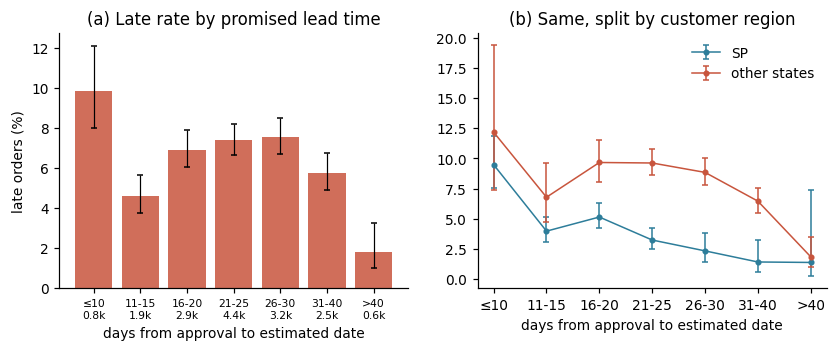

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
positions = np.arange(len(LEAD_LABELS))
axes[0].bar(positions, lead_all["late_rate"] * 100, color=LATE, alpha=0.85)
axes[0].errorbar(positions, lead_all["late_rate"] * 100,
                 yerr=[(lead_all["late_rate"] - lead_all["ci_low"]) * 100, (lead_all["ci_high"] - lead_all["late_rate"]) * 100],
                 fmt="none", color="black", lw=0.8, capsize=2)
axes[0].set_xticks(positions, [f"{label}\n{n / 1000:.1f}k" for label, n in zip(LEAD_LABELS, lead_all["orders"])], fontsize=7)
axes[0].set_xlabel("days from approval to estimated date")
axes[0].set_ylabel("late orders (%)")
axes[0].set_title("(a) Late rate by promised lead time")
for region, colour in [("SP", ON_TIME), ("other states", LATE)]:
    part = lead_region.loc[region].reindex(LEAD_LABELS)
    axes[1].errorbar(positions, part["late_rate"] * 100,
                     yerr=[(part["late_rate"] - part["ci_low"]) * 100, (part["ci_high"] - part["late_rate"]) * 100],
                     marker="o", ms=3, capsize=2, lw=1, color=colour, label=region)
axes[1].set_xticks(positions, LEAD_LABELS)
axes[1].set_xlabel("days from approval to estimated date")
axes[1].set_title("(b) Same, split by customer region")
axes[1].legend(frameon=False)
fig.savefig(FIG / "fig2_lead_time.png")
plt.show()

### Q3 Late rate by customer state

In [35]:
by_state = rate_table(lab.assign(state=lab["customer_state"].fillna("unknown")), "state")
by_state["excess_late"] = by_state["late"] - by_state["orders"] * overall
by_state["share_of_all_late"] = by_state["late"] / by_state["late"].sum()
by_state = by_state.sort_values("late_rate", ascending=False)
by_state.to_csv(CHART_DATA / "fig3_state_late_rate.csv")
priority = by_state[by_state.index != "unknown"].sort_values("excess_late", ascending=False)
priority.to_csv(OUT / "03_state_priority.csv")
priority.head(8).round(3)

,orders,late,late_rate,ci_low,ci_high,excess_late,share_of_all_late
state,,,,,,,
RJ,2059,236.0,0.115,0.102,0.129,97.784,0.213
BA,529,62.0,0.117,0.093,0.147,26.490,0.056
CE,198,36.0,0.182,0.134,0.241,22.709,0.033
PE,250,37.0,0.148,0.109,0.197,20.218,0.033
MA,133,23.0,0.173,0.118,0.246,14.072,0.021
ES,301,31.0,0.103,0.074,0.142,10.795,0.028
AL,77,14.0,0.182,0.112,0.282,8.831,0.013
PA,147,16.0,0.109,0.068,0.169,6.132,0.014


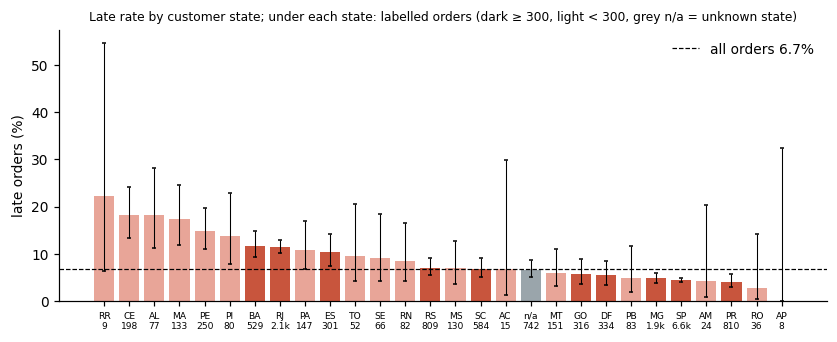

In [36]:
fig, ax = plt.subplots(figsize=(9, 3.2))
positions = np.arange(len(by_state))
colours = [GREY if state == "unknown" else (LATE if n >= 300 else "#e8a598") for state, n in zip(by_state.index, by_state["orders"])]
ax.bar(positions, by_state["late_rate"] * 100, color=colours)
ax.errorbar(positions, by_state["late_rate"] * 100,
            yerr=[(by_state["late_rate"] - by_state["ci_low"]) * 100, (by_state["ci_high"] - by_state["late_rate"]) * 100],
            fmt="none", color="black", lw=0.7, capsize=1.5)
ax.axhline(overall * 100, color="black", lw=0.8, ls="--", label=f"all orders {overall:.1%}")
tick_labels = [f"{'n/a' if state == 'unknown' else state}\n{n / 1000:.1f}k" if n >= 1000 else f"{'n/a' if state == 'unknown' else state}\n{n}"
               for state, n in zip(by_state.index, by_state["orders"])]
ax.set_xticks(positions, tick_labels, fontsize=6)
ax.set_ylim(bottom=0)
ax.set_ylabel("late orders (%)")
ax.set_title("Late rate by customer state; under each state: labelled orders (dark ≥ 300, light < 300, grey n/a = unknown state)", fontsize=8)
ax.legend(frameon=False)
fig.savefig(FIG / "fig3_states.png")
plt.show()

### Where in the delivery chain are late orders lost?

Seller handover = approval to carrier pickup, transit = carrier pickup to customer. Carrier dates are used here only to explain delays, never as features.
Orders with a missing carrier date or a pickup before approval are left out of this table.

In [37]:
NORTH_EAST = ["AL", "CE", "MA", "PB", "PE", "PI", "RN", "SE"]
lab["handover_days"] = (lab["carrier_at"] - lab["approved_at"]).dt.total_seconds() / 86400
lab["transit_days"] = (lab["delivered_at"] - lab["carrier_at"]).dt.total_seconds() / 86400
lab["state_group"] = np.select(
    [lab["customer_state"] == "RJ", lab["customer_state"] == "BA", lab["customer_state"].isin(NORTH_EAST), lab["customer_state"] == "SP"],
    ["RJ", "BA", "North-East (8 states)", "SP"],
    default="other states",
)
chained = lab[(lab["handover_days"] >= 0) & lab["transit_days"].notna()]
chain = chained.groupby("state_group").agg(orders=("transit_days", "size"), late_rate=("delivered_after_estimate", "mean"))
medians = chained.groupby(["state_group", "delivered_after_estimate"])[["handover_days", "transit_days"]].median().unstack()
medians.columns = [f"{column}_{'late' if late else 'on_time'}" for column, late in medians.columns]
chain = chain.join(medians).reindex(["RJ", "BA", "North-East (8 states)", "SP", "other states"]).round(3)
chain.to_csv(OUT / "03_delivery_chain.csv")
print("orders in this table:", len(chained), "of", len(lab))
print(chained.groupby("delivered_after_estimate")[["handover_days", "transit_days"]].median().round(1))
chain

orders in this table: 15657 of 16491
                          handover_days  transit_days
delivered_after_estimate                             
0.0                                 1.8           6.9
1.0                                 3.1          27.2


,orders,late_rate,handover_days_on_time,handover_days_late,transit_days_on_time,transit_days_late
state_group,,,,,,
RJ,1953,0.117,1.828,2.849,7.952,30.953
BA,496,0.125,1.789,2.159,12.989,30.593
North-East (8 states),926,0.146,1.834,2.763,13.333,33.355
SP,6246,0.044,1.787,4.237,4.205,14.170
other states,6036,0.060,1.816,2.939,8.087,27.688


### Sensitivity: which records are included

I recompute the main numbers with other inclusion rules. The unreliable groups are added with their recorded dates taken at face value.

In [38]:
plausible = orders["delivered_at"].notna() & orders["estimated_at"].notna() & ~impossible
face_value = (orders["delay_days"] > 0).astype(float)
fixed_item_orders = set(change_log.loc[change_log["table"] == "order_items", "key"].str.split("/").str[0])
main = orders["label_status"] == "labelled"
scenarios = {
    "main: reliable labels": main,
    "+ unknown status with plausible dates": main | ((orders["label_status"] == "unknown status") & plausible),
    "+ cancelled with plausible dates": main | ((orders["label_status"] == "cancelled") & plausible),
    "+ impossible chronology at face value": main | (orders["label_status"] == "impossible chronology"),
    "only orders with no repaired field": main & (orders["state_source"] == "recorded") & orders["approved_at"].notna() & ~orders["order_id"].isin(fixed_item_orders),
    "zip-recovered states set to unknown": main,
}
rows = []
for name, mask in scenarios.items():
    part = orders[mask].assign(delivered_after_estimate=face_value[mask])
    if name.startswith("zip"):
        part.loc[part["state_source"] == "zip prefix", "customer_state"] = np.nan
    part_rate = part["delivered_after_estimate"].mean()
    states = rate_table(part.assign(state=part["customer_state"]), "state")
    states["excess_late"] = states["late"] - states["orders"] * part_rate
    low, high = wilson(part["delivered_after_estimate"].sum(), len(part))
    rows.append({
        "scenario": name,
        "orders": len(part),
        "late_rate": round(part_rate, 4),
        "ci": f"{low:.3f}-{high:.3f}",
        "top_3_states_by_excess_late": ", ".join(states.sort_values("excess_late", ascending=False).index[:3]),
        "top_3_states_by_rate_n300": ", ".join(states[states["orders"] >= 300].sort_values("late_rate", ascending=False).index[:3]),
        "orders_unknown_state": int(part["customer_state"].isna().sum()),
    })
sensitivity = pd.DataFrame(rows)
sensitivity.to_csv(OUT / "03_sensitivity.csv", index=False)
sensitivity

,scenario,orders,late_rate,ci,top_3_states_by_excess_late,top_3_states_by_rate_n300,orders_unknown_state
0,main: reliable labels,16491,0.0671,0.063-0.071,"RJ, BA, CE","BA, RJ, ES",742
1,+ unknown status with plausible dates,17271,0.0679,0.064-0.072,"RJ, BA, CE","BA, RJ, ES",742
2,+ cancelled with plausible dates,17222,0.0666,0.063-0.070,"RJ, BA, CE","BA, RJ, ES",742
3,+ impossible chronology at face value,17273,0.0641,0.061-0.068,"RJ, BA, CE","BA, RJ, ES",742
4,only orders with no repaired field,13281,0.0680,0.064-0.072,"RJ, BA, PE","BA, RJ, RS",0
5,zip-recovered states set to unknown,16491,0.0671,0.063-0.071,"RJ, BA, CE","BA, RJ, RS",1676


In [39]:
eda_outputs = [FIG / "fig1_delays.png", FIG / "fig2_lead_time.png", FIG / "fig3_states.png", OUT / "03_q1_summary.csv",
               OUT / "03_state_priority.csv", OUT / "03_delivery_chain.csv", OUT / "03_sensitivity.csv"] + sorted(CHART_DATA.glob("*.csv"))
eda_measured = stop_monitor(monitor)
log_step("3 exploratory analysis", eda_measured, 40, len(lab), eda_outputs)
eda_measured

{'peak_mb': 67.8, 'seconds': 0.53}

## Step 4 Feature engineering

One row per retained order = labelled order with at least one item and a known approval or purchase time.
Only information available at approval is used: basket, prices, freight, estimated date, customer location, product and seller attributes.
Payments, status, carrier/delivery dates, reviews and `shipping_limit_date` are not used.

**Estimate.** A copy of the items of retained orders (21k rows × 30 columns, about 15 MB) and the feature table
(16k rows × ~65 columns × 8 B ≈ 8 MB), so about 30 MB.

In [40]:
monitor = start_monitor()
retained_mask = (orders["label_status"] == "labelled") & (orders["n_item_rows"] > 0) & (orders["approved_at"].notna() | orders["purchase_at"].notna())
print("labelled:", (orders["label_status"] == "labelled").sum(), "| retained:", retained_mask.sum(),
      "| labelled without items:", ((orders["label_status"] == "labelled") & (orders["n_item_rows"] == 0)).sum())
base = orders[retained_mask].set_index("order_id")

f_items = items[items["order_id"].isin(base.index)].copy()
product_columns = ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm",
                   "product_photos_qty", "product_description_lenght"]
f_items["catalogue_missing"] = f_items[product_columns].isna().any(axis=1)
f_items["price_imputed"] = f_items["price"].isna()
f_items["price"] = f_items["price"].fillna(f_items.groupby("product_id")["price"].transform("median")).fillna(f_items["price"].median())
f_items["freight_value"] = f_items["freight_value"].fillna(f_items.groupby("product_id")["freight_value"].transform("median")).fillna(f_items["freight_value"].median())
for column in product_columns:
    f_items[column] = f_items[column].fillna(f_items[column].median())
f_items["volume_l"] = f_items["product_length_cm"] * f_items["product_height_cm"] * f_items["product_width_cm"] / 1000
f_items["max_side_cm"] = f_items[["product_length_cm", "product_height_cm", "product_width_cm"]].max(axis=1)
f_items["customer_state"] = f_items["order_id"].map(base["customer_state"])
f_items["seller_same_state"] = (f_items["seller_state"] == f_items["customer_state"]).astype(int)
f_items["seller_in_sp"] = (f_items["seller_state"] == "SP").astype(int)
f_items["seller_state_unknown"] = f_items["seller_state"].isna().astype(int)

basket_features = f_items.groupby("order_id").agg(
    n_items=("order_item_id", "size"),
    n_products=("product_id", "nunique"),
    n_sellers=("seller_id", "nunique"),
    price_total=("price", "sum"),
    price_max=("price", "max"),
    freight_total=("freight_value", "sum"),
    weight_total_kg=("product_weight_g", lambda s: s.sum() / 1000),
    volume_total_l=("volume_l", "sum"),
    max_side_cm=("max_side_cm", "max"),
    photos_mean=("product_photos_qty", "mean"),
    description_length_mean=("product_description_lenght", "mean"),
    catalogue_missing_share=("catalogue_missing", "mean"),
    price_imputed_share=("price_imputed", "mean"),
    seller_same_state_share=("seller_same_state", "mean"),
    seller_in_sp_share=("seller_in_sp", "mean"),
    seller_state_unknown_share=("seller_state_unknown", "mean"),
)
main_category = f_items.sort_values("price", ascending=False).drop_duplicates("order_id").set_index("order_id")["category"]

approval = base["approved_at"].fillna(base["purchase_at"])
features = pd.DataFrame(index=base.index)
features["lead_days"] = (base["estimated_at"].dt.normalize() - approval.dt.normalize()).dt.days
features["approval_wait_hours"] = (base["approved_at"] - base["purchase_at"]).dt.total_seconds() / 3600
features["approval_wait_missing"] = features["approval_wait_hours"].isna().astype(int)
features["approval_wait_hours"] = features["approval_wait_hours"].fillna(features["approval_wait_hours"].median())
features["approval_time_imputed"] = base["approved_at"].isna().astype(int)
features["approval_month"] = approval.dt.month
features["approval_weekday"] = approval.dt.dayofweek
features["approval_hour"] = approval.dt.hour
features["estimate_weekday"] = base["estimated_at"].dt.dayofweek
features = features.join(basket_features)
features["freight_share"] = features["freight_total"] / (features["price_total"] + features["freight_total"])
features["freight_share"] = features["freight_share"].fillna(0)

category_group = main_category.fillna("unknown")
top_categories = category_group.value_counts().index[:10]
category_group = category_group.where(category_group.isin(top_categories) | (category_group == "unknown"), "other")
features = features.join(pd.get_dummies(category_group, prefix="category", dtype=int))
state_group = base["customer_state"].fillna("unknown")
features = features.join(pd.get_dummies(state_group, prefix="state", dtype=int))
features = features.loc[base.index]

labels = pd.DataFrame({"order_id": base.index, "delivered_after_estimate": base["delivered_after_estimate"].astype(int).values})
assert len(features) == len(labels) and (features.index == labels["order_id"]).all()
assert features.notna().all().all()
print(features.shape, "| memory", frame_mb(features), "MB")

labelled: 16491 | retained: 16491 | labelled without items: 0


(16491, 64) | memory 9.52 MB


**Checks against leakage.** No feature name contains a forbidden source, and no single feature is suspiciously strong
(a leaked delivery field would correlate almost perfectly with the label).

In [41]:
FORBIDDEN = ["deliver", "carrier", "payment", "paid", "review", "status", "shipping_limit", "delay", "label"]
assert not [column for column in features.columns if any(word in column for word in FORBIDDEN)]
correlation = features.corrwith(pd.Series(labels["delivered_after_estimate"].values, index=features.index)).rename("correlation_with_label")
correlation.to_csv(OUT / "04_feature_label_correlation.csv")
print("largest absolute correlation:", correlation.abs().max().round(3))
correlation.reindex(correlation.abs().sort_values(ascending=False).index).head(10).round(3)

largest absolute correlation: 0.075


state_SP                  -0.075
state_RJ                   0.072
seller_same_state_share   -0.061
state_CE                   0.051
state_PE                   0.040
state_MA                   0.038
state_BA                   0.036
seller_in_sp_share         0.033
lead_days                 -0.032
freight_total              0.032
Name: correlation_with_label, dtype: float64

In [42]:
meaning = {
    "lead_days": ("calendar days from approval to the estimated delivery date", "approved_at (or purchase), estimated date"),
    "approval_wait_hours": ("hours from purchase to approval (median if unknown)", "purchase, approval"),
    "approval_wait_missing": ("1 if purchase or approval time is unknown", "purchase, approval"),
    "approval_time_imputed": ("1 if approval time is unknown and purchase time is used", "approval"),
    "approval_month": ("month of approval, 1-12", "approval"),
    "approval_weekday": ("weekday of approval, 0 = Monday", "approval"),
    "approval_hour": ("hour of approval, local clock", "approval"),
    "estimate_weekday": ("weekday of the estimated date", "estimated date"),
    "n_items": ("number of items", "items"),
    "n_products": ("number of different products", "items"),
    "n_sellers": ("number of different sellers", "items"),
    "price_total": ("sum of item prices, BRL", "items"),
    "price_max": ("most expensive item, BRL", "items"),
    "freight_total": ("sum of freight, BRL", "items"),
    "freight_share": ("freight / (price + freight)", "items"),
    "weight_total_kg": ("total product weight, kg", "products"),
    "volume_total_l": ("total product volume, litres", "products"),
    "max_side_cm": ("longest side of any product, cm", "products"),
    "photos_mean": ("mean number of product photos", "products"),
    "description_length_mean": ("mean product description length, characters", "products"),
    "catalogue_missing_share": ("share of items with a missing catalogue field (median used)", "products"),
    "price_imputed_share": ("share of items whose price was missing and imputed", "items"),
    "seller_same_state_share": ("share of items sold from the customer's state", "sellers, customers"),
    "seller_in_sp_share": ("share of items sold from SP", "sellers"),
    "seller_state_unknown_share": ("share of items whose seller state is unknown", "sellers"),
}
dictionary = []
for column in features.columns:
    if column.startswith("category_"):
        dictionary.append((column, f"1 if the most expensive item is in category '{column[9:]}'", "products"))
    elif column.startswith("state_"):
        dictionary.append((column, f"1 if the customer state is {column[6:]}", "customers"))
    else:
        dictionary.append((column, *meaning[column]))
dictionary = pd.DataFrame(dictionary, columns=["feature", "meaning", "source"])

features.reset_index(drop=True).to_parquet(OUT / "04_features.parquet", index=False)
labels.to_csv(OUT / "04_labels.csv", index=False)
dictionary.to_csv(OUT / "04_feature_dictionary.csv", index=False)
exclusions = pd.Series({
    "orders in source": len(orders),
    "not labelled (see 02_label_accounting.csv)": int((orders["label_status"] != "labelled").sum()),
    "labelled but no items": int(((orders["label_status"] == "labelled") & (orders["n_item_rows"] == 0)).sum()),
    "labelled but no approval or purchase time": int(((orders["label_status"] == "labelled") & (orders["n_item_rows"] > 0) & orders["approved_at"].isna() & orders["purchase_at"].isna()).sum()),
    "retained in feature table": len(features),
})
exclusions.to_csv(OUT / "04_exclusions.csv")
assert exclusions.iloc[1:4].sum() + len(features) == len(orders)
log_step("4 features", stop_monitor(monitor), 30, len(features),
         [OUT / "04_features.parquet", OUT / "04_labels.csv", OUT / "04_feature_dictionary.csv", OUT / "04_exclusions.csv", OUT / "04_feature_label_correlation.csv"])
print(exclusions.to_dict())
print("late rate in feature table:", labels["delivered_after_estimate"].mean().round(4))
dictionary.head(30)

{'orders in source': 20000, 'not labelled (see 02_label_accounting.csv)': 3509, 'labelled but no items': 0, 'labelled but no approval or purchase time': 0, 'retained in feature table': 16491}
late rate in feature table: 0.0671


,feature,meaning,source
0,lead_days,calendar days from approval to the estimated d...,"approved_at (or purchase), estimated date"
1,approval_wait_hours,hours from purchase to approval (median if unk...,"purchase, approval"
2,approval_wait_missing,1 if purchase or approval time is unknown,"purchase, approval"
3,approval_time_imputed,1 if approval time is unknown and purchase tim...,approval
4,approval_month,"month of approval, 1-12",approval
5,approval_weekday,"weekday of approval, 0 = Monday",approval
6,approval_hour,"hour of approval, local clock",approval
7,estimate_weekday,weekday of the estimated date,estimated date
8,n_items,number of items,items
9,n_products,number of different products,items


## Step 5 Reproducibility: resources per step

`peak_rss_growth_mb` is measured, `estimated_peak_mb` comes from the size reasoning written above each step.
`saved_mb` is the size of the files the step writes. The SQLite file is the only intermediate that is not a final output, it can be deleted after the run.

In [43]:
resource_table = pd.DataFrame(resources)
resource_table.loc[len(resource_table)] = {
    "step": "total", "seconds": resource_table["seconds"].sum(), "peak_rss_growth_mb": resource_table["peak_rss_growth_mb"].max(),
    "estimated_peak_mb": resource_table["estimated_peak_mb"].max(), "rows_out": np.nan,
    "saved_mb": round(sum(path.stat().st_size for path in OUT.rglob("*") if path.is_file()) / 1e6, 2),
    "temporary_mb": resource_table["temporary_mb"].sum(), "outputs": "outputs/",
}
resource_table.to_csv(OUT / "05_resources.csv", index=False)
max_rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
process_peak_mb = max_rss / 1e6 if sys.platform == "darwin" else max_rss / 1e3
print("peak RSS of the whole notebook process:", round(process_peak_mb, 1), "MB")
con.close()
resource_table

peak RSS of the whole notebook process: 674.9 MB


,step,seconds,peak_rss_growth_mb,estimated_peak_mb,rows_out,saved_mb,temporary_mb,outputs
0,0 build database,0.24,185.4,60.3,116981.0,24.36,0.00,00_marketplace.sqlite
1,1 load one row per order,0.18,37.0,19.8,20000.0,3.36,5.29,"01_orders_loaded.parquet, 01_checks.csv, 01_re..."
2,2 clean and label,0.48,66.9,65.0,20000.0,6.83,0.00,"02_orders_clean.parquet, 02_items_clean.parque..."
3,3 exploratory analysis,0.53,67.8,40.0,16491.0,0.25,0.00,"fig1_delays.png, fig2_lead_time.png, fig3_stat..."
4,4 features,0.23,34.8,30.0,16491.0,1.17,0.00,"04_features.parquet, 04_labels.csv, 04_feature..."
5,total,1.66,185.4,65.0,NaN,35.98,5.29,outputs/


In [44]:
inventory = pd.DataFrame([
    {"file": str(path.relative_to(ROOT)), "mb": round(path.stat().st_size / 1e6, 3)}
    for path in sorted(OUT.rglob("*")) if path.is_file()
])
inventory.to_csv(OUT / "05_file_inventory.csv", index=False)
inventory

,file,mb
0,outputs/00_marketplace.sqlite,24.363
1,outputs/01_checks.csv,0.000
2,outputs/01_load_comparison.csv,0.000
3,outputs/01_orders_loaded.parquet,3.356
4,outputs/01_relationships.csv,0.000
5,outputs/01_tables.csv,0.000
6,outputs/02_change_log.csv,1.139
7,outputs/02_change_summary.csv,0.002
8,outputs/02_issues.csv,0.002
9,outputs/02_items_clean.parquet,2.240
